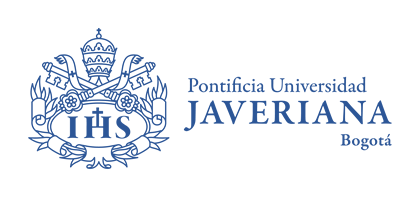
# Aprendizeje Profundo
## Taller 2 — Aprendizaje profundo por refuerzo


**Objetivo:**

Implementar, entrenar y evaluar un agente de aprendizaje profundo por refuerzo mediante Double Deep Q-Network (Double DQN) en un entorno Atari, analizando las decisiones de diseño de la arquitectura neuronal, la estrategia de exploración y el proceso de aprendizaje de la función de valor Q.

**Requisitos:** Python 3.10+, Jupyter o Colab, preferiblemente GPU. El entrenamiento completo de Atari puede requerir millones de interacciones, tome conclusiones y métricas con lo que alcance a probar.

Siga las instrucciones de entrega de talleres contempladas en la presentación de inicio del curso

# Estudiante: Daniel Sebastian Velasco Munar

### ¿Qué son ALE y Gymnasium?

Para el desarrollo de este taller de Aprendizaje por Refuerzo, dependemos de dos librerías fundamentales que estructuran la interacción del agente con el entorno de Atari:

1. **ALE (Arcade Learning Environment):**
   - Es una plataforma de software diseñada para evaluar y desarrollar agentes de inteligencia artificial de propósito general.
   - Actúa como un emulador interno del sistema **Atari 2600**, permitiendo que programas externos interactúen con decenas de videojuegos clásicos (como *Pong*, *Breakout*, *Space Invaders*, entre otros).
   - Proporciona acceso directo a la señal de video (los píxeles en pantalla), la puntuación (recompensa) y la memoria del sistema (RAM), emulando los controles de la consola original.

2. **Gymnasium:**
   - Es un fork mantenido activamente de la clásica librería `Gym` de OpenAI.
   - Ofrece una **interfaz estándar unificada** para problemas de aprendizaje por refuerzo en Python.
   - Define la estructura básica del ciclo de interacción del agente a través de una API común:
     - El método `reset()` para inicializar el entorno.
     - El método `step(action)` para ejecutar una acción y recibir la nueva observación, recompensa e indicadores de término (`terminated` y `truncated`).
   - En este notebook, Gymnasium actúa como la capa superior que envuelve a **ALE** (`ALE/Pong-v5`), permitiendo aplicar wrappers estandarizados (como `AtariPreprocessing` y `FrameStackObservation`) de manera limpia y modular.

In [1]:
# Instalación de dependencias (Colab ya trae TensorFlow; torch no se usa en este notebook)
!pip install -q "gymnasium>=1.1,<2" "ale-py>=0.11,<1" matplotlib numpy imageio

In [2]:
import random
from collections import deque
from dataclasses import dataclass
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
import ale_py
import imageio
from IPython.display import Image, display



In [3]:
gym.register_envs(ale_py)
SEED = 42
random.seed(SEED); np.random.seed(SEED);

### Descripción General de la API de Gymnasium

El núcleo de Gymnasium se basa en un ciclo de interacción continuo entre el **Agente** y el **Entorno** (*Environment*). El flujo estándar de trabajo utiliza los siguientes componentes clave:

* **`gym.make(env_id, ...)`**: Instancia el entorno a partir de su identificador (en nuestro caso, `"ALE/Pong-v5"`). Aquí se puede configurar el modo de renderizado (por ejemplo, `render_mode="rgb_array"`).
* **`env.reset(seed=...)`**: Inicializa el entorno a un estado inicial. Es crucial para la reproducibilidad pasar una semilla (`seed`). Retorna una tupla con:
  - `observation`: El estado inicial del entorno.
  - `info`: Un diccionario con metadatos útiles específicos del juego (p. ej., número de vidas).
* **`env.step(action)`**: Ejecuta una acción elegida por el agente y devuelve cinco valores esenciales:
  1. `observation`: El nuevo estado (píxeles, vectores, etc.) tras aplicar la acción.
  2. `reward`: Una señal escalar (número flotante) que indica el beneficio inmediato de la acción.
  3. `terminated`: Un booleano que indica si el agente alcanzó un estado terminal natural de fin de juego (ganar, perder o morir).
  4. `truncated`: Un booleano que indica si el episodio terminó de manera forzada debido a un límite de tiempo o condición externa.
  5. `info`: Información de diagnóstico auxiliar.
* **`env.close()`**: Libera de forma segura los recursos del sistema y las ventanas gráficas del emulador al finalizar la interacción.

## 1. Crear y explorar un entorno Atari

En la siguiente celda se instancia un gimnasio de ALE usando el API de OpenGymnasium. Podemos obtener el espacio de observaciones (obs. del entorno), el espacio de acciones del entorno y las acciones que pueden ser realizadas en el

Espacio de observaciones: Box(0, 255, (210, 160, 3), uint8)
Espacio de acciones: Discrete(6)
Forma / tipo: (210, 160, 3) uint8
Espacio de acciones Discrete(6)
Acciones: ['NOOP', 'FIRE', 'RIGHT', 'LEFT', 'RIGHTFIRE', 'LEFTFIRE']


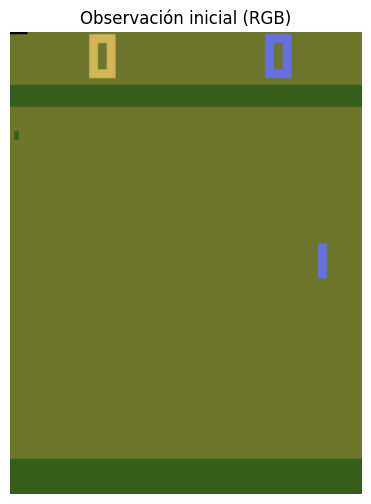

In [4]:
# Instanciamos modelo PONG
probe = gym.make("ALE/Pong-v5", render_mode="rgb_array")
# Se inicia el gimnasio en un estado inicial
obs, info = probe.reset(seed=SEED)

print("Espacio de observaciones:", probe.observation_space)
print("Espacio de acciones:", probe.action_space)
print("Forma / tipo:", obs.shape, obs.dtype)
print("Espacio de acciones", probe.action_space)
print("Acciones:", probe.unwrapped.get_action_meanings())
plt.figure(figsize=(5,6))
plt.imshow(obs); plt.axis("off"); plt.title("Observación inicial (RGB)"); plt.show()
probe.close()

Escojamos de forma aleatoria una serie de acciones mediante `probe.action_space.sample()`





Recompensas distintas (muestra): [-1.0, 0.0]


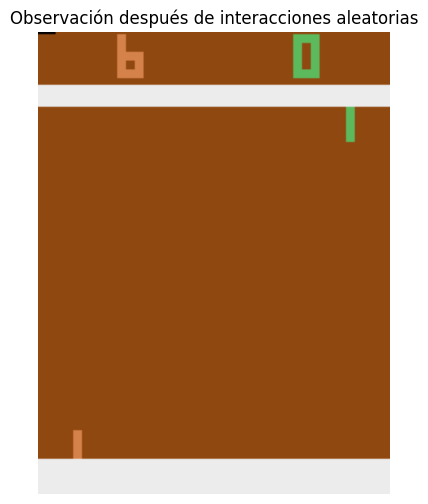

In [5]:
probe = gym.make("ALE/Pong-v5", render_mode="rgb_array")
obs, info = probe.reset(seed=SEED)
rewards = []
obs_history=[]
obs_history.append(obs)
for t in range(300):
    action = probe.action_space.sample()
    obs, reward, terminated, truncated, info = probe.step(action)
    obs_history.append(obs)
    rewards.append(reward)
    if terminated or truncated:
        # Reinicia el juego
        obs, info = probe.reset()

print("Recompensas distintas (muestra):", sorted(set(rewards)))
plt.figure(figsize=(5,6)); plt.imshow(obs); plt.axis("off")
plt.title("Observación después de interacciones aleatorias"); plt.show()
probe.close()

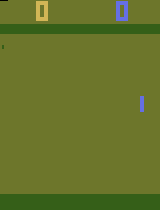

In [6]:


# Guardar el historial de observaciones como un archivo GIF animado
gif_path = "random_agent_pong.gif"
# Guardamos cada frame reduciendo el muestreo para mantener un archivo ligero (un frame cada 2 pasos)
imageio.mimsave(gif_path, obs_history[::2], fps=30)

# Mostrar el GIF directamente en el notebook
display(Image(filename=gif_path))

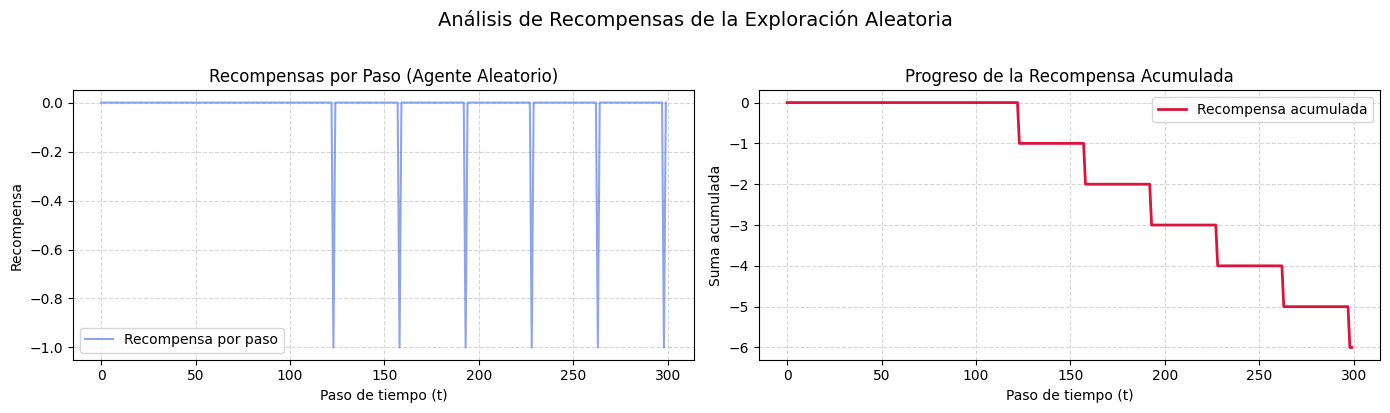

In [7]:
# Graficar las recompensas obtenidas durante la interacción aleatoria
cumulative_rewards = np.cumsum(rewards)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Gráfico 1: Recompensas individuales
axes[0].plot(rewards, color='royalblue', alpha=0.6, label='Recompensa por paso')
axes[0].set_title('Recompensas por Paso (Agente Aleatorio)')
axes[0].set_xlabel('Paso de tiempo (t)')
axes[0].set_ylabel('Recompensa')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend()

# Gráfico 2: Recompensa acumulada
axes[1].plot(cumulative_rewards, color='crimson', linewidth=2, label='Recompensa acumulada')
axes[1].set_title('Progreso de la Recompensa Acumulada')
axes[1].set_xlabel('Paso de tiempo (t)')
axes[1].set_ylabel('Suma acumulada')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend()

plt.suptitle('Análisis de Recompensas de la Exploración Aleatoria', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 2. Simulación con agente Heurístico

Para explorar mejor el juego, podemos implementar una política simple que emule el comportamiento humano básico: seguir la posición vertical de la pelota. Aunque no es perfecta por el retraso de la emulación, nos da una visión mucho más realista de la dinámica de Pong.

In [8]:
# Reiniciamos el entorno para obtener imágenes limpias
probe = gym.make("ALE/Pong-v5", render_mode="rgb_array")
obs, info = probe.reset(seed=SEED)

# Heurística simple: Seguir la pelota en el eje Y
# En Pong de Atari, la raqueta derecha (nuestra) es de color verde y se mueve con:
# 2 (RIGHT / UP) y 3 (LEFT / DOWN)

def heuristic_agent(obs):
    # El área de juego útil excluye los bordes y el marcador (Y entre 34 y 194)
    play_area = obs[34:194, :, :]

    # Buscar los píxeles claros de la pelota (generalmente de color blanco/grisáceo)
    ball_pixels = np.argwhere((play_area[:, :, 0] > 140) & (play_area[:, :, 1] > 140))
    if len(ball_pixels) > 0:
        ball_y = ball_pixels[:, 0].mean() + 34
    else:
        ball_y = 110 # Posición central si no se detecta la pelota

    # Encontrar nuestra raqueta (barra verde en el extremo derecho, x aprox 140-144)
    # El verde característico de la raqueta tiene una alta intensidad en el canal G (verde) y baja en R y B
    paddle_pixels = np.argwhere((obs[34:194, 140:144, 1] > 100) & (obs[34:194, 140:144, 0] < 100))
    if len(paddle_pixels) > 0:
        paddle_y = paddle_pixels[:, 0].mean() + 34
    else:
        paddle_y = 110 # En caso de que se oculte o no se detecte, mantener el centro

    # Decidir acción basada en la diferencia de posiciones
    if ball_y < paddle_y - 2:
        return 2  # Subir (UP)
    elif ball_y > paddle_y + 2:
        return 3  # Bajar (DOWN)
    return 0  # Quieto (NOOP)

# Ejecutar demostración con el agente corregido
frames = []
rewards = []
for t in range(500):
    action = heuristic_agent(obs)
    obs, reward, terminated, truncated, info = probe.step(action)
    rewards.append(reward)
    # Guardar todos los frames para la generación del GIF
    frames.append(obs)
    if terminated or truncated:
        break

probe.close()
print("Recompensas obtenidas en este fragmento:", set(rewards))

Recompensas obtenidas en este fragmento: {0.0, -1.0}


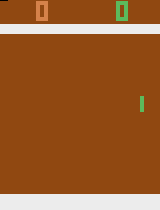

In [9]:


heuristic_gif_path = "heuristic_agent_pong.gif"
imageio.mimsave(heuristic_gif_path, frames, fps=30)

# Mostrar el GIF generado
display(Image(filename=heuristic_gif_path))

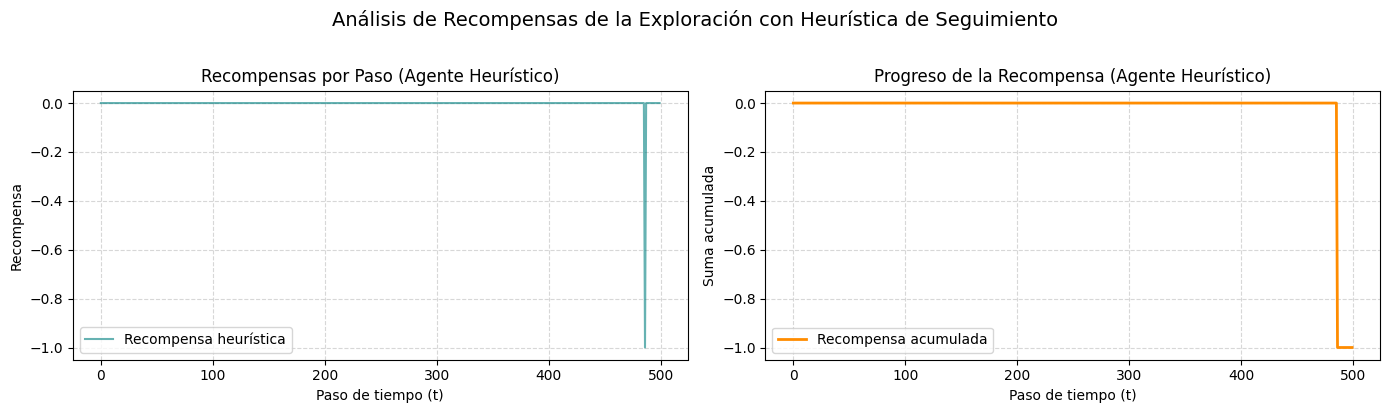

In [10]:
# Graficar las recompensas de la simulación heurística
heuristic_cumulative = np.cumsum(rewards)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Gráfico 1: Recompensas por paso
axes[0].plot(rewards, color='teal', alpha=0.6, label='Recompensa heurística')
axes[0].set_title('Recompensas por Paso (Agente Heurístico)')
axes[0].set_xlabel('Paso de tiempo (t)')
axes[0].set_ylabel('Recompensa')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend()

# Gráfico 2: Recompensa acumulada
axes[1].plot(heuristic_cumulative, color='darkorange', linewidth=2, label='Recompensa acumulada')
axes[1].set_title('Progreso de la Recompensa (Agente Heurístico)')
axes[1].set_xlabel('Paso de tiempo (t)')
axes[1].set_ylabel('Suma acumulada')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend()

plt.suptitle('Análisis de Recompensas de la Exploración con Heurística de Seguimiento', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 3. Preprocesamiento y apilamiento temporal
PAra acelerar el procesamiento del entorno se crea una función de procesamiento del entorno $\phi$. Se utiliza una imagen en escala de grises de **84 × 84** píxeles, cuatro fotogramas consecutivos y un *frame skip* de 4 dentro de `AtariPreprocessing`.

**Importante:** configurar `frameskip=1` en el entorno base; de lo contrario se aplicaría *frame skip* tanto en el entorno como en el wrapper. Mantener las observaciones como `uint8` en memoria y normalizarlas a `[0,1]` al entrar a la red para simplificar estado



Estado preprocesado: (4, 84, 84) uint8


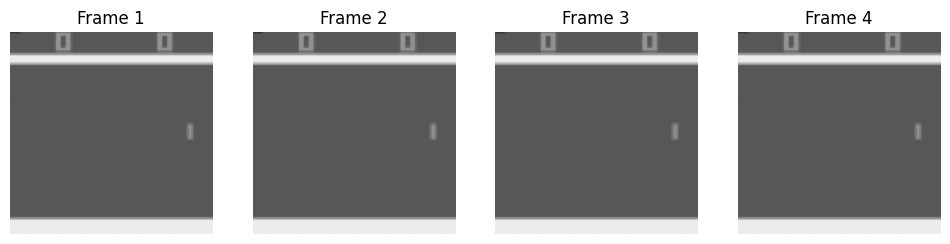

In [11]:
from gymnasium.wrappers import AtariPreprocessing, FrameStackObservation

def make_env(seed=None):
    env = gym.make("ALE/Pong-v5", frameskip=1, repeat_action_probability=0.25)
    env = AtariPreprocessing(env, noop_max=30, frame_skip=4,
                             screen_size=84, grayscale_obs=True,
                             grayscale_newaxis=False, scale_obs=False)
    env = FrameStackObservation(env, stack_size=4)
    if seed is not None:
        env.reset(seed=seed)
        env.action_space.seed(seed)
    return env

env = make_env(SEED)
state, info = env.reset(seed=SEED)
print("Estado preprocesado:", state.shape, state.dtype)
fig, axes = plt.subplots(1, 4, figsize=(12,3))
for i, ax in enumerate(axes):
    ax.imshow(state[i], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Frame {i+1}"); ax.axis("off")
plt.show()
env.close()

### 4. Implementación de Double DQN con Keras y TensorFlow

Definiremos primero la arquitectura de la Red Convolucional (Q-Network) en Keras compatible con la entrada preprocesada de dimensiones

In [12]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
from collections import deque
import random

def create_q_model(n_actions):
    n_actions = int(n_actions)

    # Entrada de (4, 84, 84). Para procesarlo en Keras de manera estándar,
    # transponemos o definimos el formato de canales como 'channels_first' (NCHW)
    inputs = layers.Input(shape=(4, 84, 84))

    # Transponer a (84, 84, 4) para usar el formato estándar 'channels_last' de CPU/GPU en Keras
    x = layers.Permute((2, 3, 1))(inputs)

    # Normalización de [0, 255] a [0.0, 1.0]
    x = layers.Lambda(lambda t: t / 255.0)(x)

    # Capas Convolucionales
    x = layers.Conv2D(32, kernel_size=8, strides=4, activation="relu")(x)
    x = layers.Conv2D(64, kernel_size=4, strides=2, activation="relu")(x)
    x = layers.Conv2D(64, kernel_size=3, strides=1, activation="relu")(x)
    x = layers.Flatten()(x)

    # Capa Densa y salida
    x = layers.Dense(512, activation="relu")(x)
    # Se calcula valor Q para todas las acciones al tiempo
    outputs = layers.Dense(n_actions, activation="linear")(x)

    return models.Model(inputs=inputs, outputs=outputs)

# Probar la creación del modelo
test_model = create_q_model(n_actions=6)
test_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 4, 84, 84)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ permute (Permute)               │ (None, 84, 84, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 84, 84, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 20, 20, 32)     │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 9, 9, 64)       │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,606,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         3,078 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,687,206 (6.44 MB)

 Trainable params: 1,687,206 (6.44 MB)

 Non-trainable params: 0 (0.00 B)

Ahora creamos el **Replay Buffer** para almacenar las transiciones `(estado, acción, recompensa, siguiente_estado, terminado)` y la clase del agente **Double DQNAgent**.

In [13]:
class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)

    def add(self, state, action, reward, next_state, done):
        self.buffer.append((np.array(state, dtype=np.uint8), action, reward, np.array(next_state, dtype=np.uint8), done))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)
        return (np.array(states, dtype=np.uint8),
                np.array(actions, dtype=np.int32),
                np.array(rewards, dtype=np.float32),
                np.array(next_states, dtype=np.uint8),
                np.array(dones, dtype=np.float32))

    def __len__(self):
        return len(self.buffer)

class DoubleDQNAgent:
    def __init__(self, n_actions, lr=1e-4, gamma=0.99, buffer_capacity=10000):
        self.n_actions = n_actions
        self.gamma = gamma

        # Red Online y Red Target
        self.model = create_q_model(n_actions)
        self.target_model = create_q_model(n_actions)
        self.update_target_network()

        self.optimizer = tf.keras.optimizers.Adam(learning_rate=lr)
        self.loss_fn = tf.keras.losses.Huber() # Huber loss / Smooth L1 equivalente
        self.buffer = ReplayBuffer(buffer_capacity)

    def update_target_network(self):
        self.target_model.set_weights(self.model.get_weights())

    def choose_action(self, state, epsilon):
        if random.random() < epsilon:
            return random.randrange(self.n_actions)
        state_tensor = tf.convert_to_tensor(np.expand_dims(state, axis=0), dtype=tf.float32)
        q_values = self.model(state_tensor, training=False)
        return int(tf.argmax(q_values[0]).numpy())

    @tf.function
    def train_step_tf(self, states, actions, rewards, next_states, dones):
        # 1. Obtener las acciones seleccionadas por la red online para el siguiente estado
        next_online_q = self.model(next_states, training=False)
        next_actions = tf.argmax(next_online_q, axis=1, output_type=tf.int32)

        # 2. Evaluar esas acciones con la red target (Lógica Double DQN)
        next_target_q = self.target_model(next_states, training=False)
        indices = tf.stack([tf.range(tf.shape(next_actions)[0]), next_actions], axis=1)
        max_next_q = tf.gather_nd(next_target_q, indices)

        # 3. Calcular los objetivos TD (TD Targets)
        targets = rewards + self.gamma * (1.0 - dones) * max_next_q

        with tf.GradientTape() as tape:
            # Obtener el Q-value estimado por la red online para las acciones tomadas
            q_values = self.model(states, training=True)
            action_indices = tf.stack([tf.range(tf.shape(actions)[0]), actions], axis=1)
            predicted_q = tf.gather_nd(q_values, action_indices)

            # Calcular pérdida
            loss = self.loss_fn(targets, predicted_q)

        # Aplicar gradientes
        grads = tape.gradient(loss, self.model.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.model.trainable_variables))
        return loss

    def train(self, batch_size):
        if len(self.buffer) < batch_size:
            return 0.0
        states, actions, rewards, next_states, dones = self.buffer.sample(batch_size)

        # Convertir a tensores
        states_t = tf.convert_to_tensor(states, dtype=tf.float32)
        actions_t = tf.convert_to_tensor(actions, dtype=tf.int32)
        rewards_t = tf.convert_to_tensor(rewards, dtype=tf.float32)
        next_states_t = tf.convert_to_tensor(next_states, dtype=tf.float32)
        dones_t = tf.convert_to_tensor(dones, dtype=tf.float32)

        loss = self.train_step_tf(states_t, actions_t, rewards_t, next_states_t, dones_t)
        return float(loss.numpy())

Definimos una pequeña rutina de demostración para verificar que el agente interactúa y entrena sin errores en el entorno Gymnasium preprocesado.

In [14]:
# Inicializar el entorno preprocesado y el agente
test_env = make_env(SEED)
state, _ = test_env.reset(seed=SEED)
n_actions = test_env.action_space.n

agent = DoubleDQNAgent(n_actions=n_actions, buffer_capacity=1000)

# Simular unas cuantas transiciones y agregarlas al Buffer para probar un paso de entrenamiento
for _ in range(2000):
    action = agent.choose_action(state, epsilon=0.5)
    next_state, reward, terminated, truncated, _ = test_env.step(action)
    agent.buffer.add(state, action, reward, next_state, terminated or truncated)
    if terminated or truncated:
        state, _ = test_env.reset()
    else:
        state = next_state

# Verificar un paso de entrenamiento
loss_train = agent.train(batch_size=16)
print(f"¡Completado con éxito! Pérdida del paso de entrenamiento: {loss_train:.6f}")
test_env.close()

¡Completado con éxito! Pérdida del paso de entrenamiento: 0.033541


### 5. Evaluación del Agente Double DQN (Keras) y Métricas a Observar

Vamos a ejecutar un episodio de evaluación usando una política codiciosa (greedy, $\epsilon = 0.05$ para permitir una mínima exploración residual o completamente determinista $\epsilon = 0$) para ver cómo se desenvuelve el agente en el entorno preprocesado. Grabaremos los fotogramas para exportar un GIF del gameplay.

In [15]:
# Crear entorno de evaluación
eval_env = make_env(seed=2026)
state, _ = eval_env.reset(seed=2026)

eval_frames = []
eval_rewards = []

# El agente jugará utilizando su red neuronal
done = False
while not done:
    # Usamos epsilon bajo o cero para evaluar el comportamiento aprendido
    action = agent.choose_action(state, epsilon=0.05)
    next_state, reward, terminated, truncated, _ = eval_env.step(action)
    eval_rewards.append(reward)

    # Renderizar y guardar el frame en su tamaño original (RGB) desde el emulador si es posible
    # Como estamos usando wrappers, podemos acceder al frame RGB original usando eval_env.unwrapped
    eval_frames.append(eval_env.unwrapped.ale.getScreenRGB())

    state = next_state
    done = terminated or truncated

eval_env.close()

print(f"Evaluación completada.")
print(f"Pasos totales del episodio: {len(eval_rewards)}")
print(f"Suma de recompensas obtenidas (Score): {sum(eval_rewards)}")

Evaluación completada.
Pasos totales del episodio: 763
Suma de recompensas obtenidas (Score): -21.0


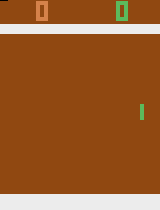

In [16]:
# Guardar el gameplay de evaluación como GIF
eval_gif_path = "keras_ddqn_eval.gif"
imageio.mimsave(eval_gif_path, eval_frames[::3], fps=30) # Muestreo de frames para optimizar tamaño

# Mostrar el GIF en el notebook
display(Image(filename=eval_gif_path))

## Actividades del taller

A partir de los conceptos indicados en el notebook, desarrolle las siguientes actividades:

**Nota:** No es necesario que use esta red o este notebook, si lo desea puede usar otro notebook u otro framework para RL.

1. **Ajuste del ciclo de entrenamiento**

Complete el ciclo de entrenamiento del agente de acuerdo con el funcionamiento de Double DQN estudiado en clase. Verifique que se implementen correctamente los mecanismos de selección de acciones, almacenamiento y muestreo de experiencias, actualización de la red neuronal y sincronización de la red objetivo.

Ejecute el entrenamiento durante múltiples episodios, ajustando los parámetros y el presupuesto de entrenamiento hasta observar una mejora en la política aprendida por el agente.

2. **Experimentación con la estrategia de exploración**

Analice el efecto de la estrategia ε-greedy sobre el aprendizaje del agente. Experimente con diferentes valores iniciales, mínimos y tasas de disminución de ε.


3. **Análisis de las predicciones de la función Q**

Examine el comportamiento de los valores Q estimados por la red neuronal durante el entrenamiento y compárelos con los objetivos calculados mediante Double DQN.

Analice la evolución del error de diferencia temporal (Temporal Difference Error) e identifique posibles problemas de aprendizaje, como estimaciones inestables, sobreestimación de los valores Q o ausencia de mejoras en las recompensas obtenidas.

Tenga presente que los objetivos TD corresponden a estimaciones utilizadas para entrenar la red y no necesariamente a los valores Q óptimos o reales.

4. **Revisión de la arquitectura neuronal**

El notebook proporciona una arquitectura neuronal inicial, tanto para el procesamiento convolucional de las observaciones visuales como para la aproximación de la función Q.

Revise críticamente esta arquitectura y evalúe si es adecuada para el problema abordado. Considere aspectos como la cantidad de capas, el número y tamaño de filtros convolucionales, las funciones de activación y las capas densas utilizadas para estimar los valores Q de las acciones.

Proponga y evalúe al menos una modificación justificada de la arquitectura o de su configuración. Compare sus resultados con los obtenidos utilizando la arquitectura inicial.

5. **Evaluación de la política aprendida**

Evalúe el desempeño del agente después del entrenamiento, utilizando una política predominantemente basada en las acciones estimadas como óptimas por la red.

Compare su comportamiento con el del agente empírico implementado que selecciona acciones siguiendo la bola y analice si los resultados evidencian un aprendizaje efectivo.


**Nota:** Las actividades propuestas no deben abordarse necesariamente de manera secuencial ni como tareas independientes. Se espera que, a medida que avance en la experimentación, identifique las dificultades de aprendizaje del agente y realice los ajustes que considere necesarios en la arquitectura, los hiperparámetros y el proceso de entrenamiento, con el objetivo de obtener una política que permita al agente jugar Pong de manera efectiva. Debe variar al menos una vez los elementos solicitados.

Elabore un informe en el que documente y justifique las decisiones tomadas, describa los experimentos realizados y analice críticamente los resultados obtenidos, considerando los aspectos señalados anteriormente. El informe debe seguir las reglas de presentación y elaboración establecidas en la primera sesión de clase.

## 6. Desarrollo del taller

Desde aquí está la solución. Se reutilizan `make_env`, `create_q_model` y `heuristic_agent` de las secciones anteriores; lo nuevo es el ciclo de entrenamiento, el registro de métricas y los experimentos.

**Presupuesto de cómputo (Colab gratis, GPU T4).** Pong con DQN suele necesitar del orden de un millón de pasos para jugar bien, y en Colab gratis no hay tiempo para hacer eso en cada experimento. Se planearon estas corridas:

| Corrida | Qué cambia frente a `base` | Pasos |
|---|---|---|
| `base` | configuración de referencia (red original del notebook) | 600 000 |
| `eps_rapido` | ε llega a 0.02 en 20 000 pasos | 250 000 |
| `eps_lento` | ε baja solo hasta 0.10 y tarda 250 000 pasos | 250 000 |
| `dueling` | cabeza Dueling en lugar de la capa densa original | 250 000 |

Un paso es una decisión del agente; con `frame_skip=4` equivale a 4 cuadros del juego. Las comparaciones se hacen sobre los primeros 250 000 pasos de cada corrida, con la misma semilla y los mismos pesos iniciales, para que la única diferencia sea lo que se cambia. La corrida `base` sigue hasta 600 000 pasos para la evaluación final.

**Cortes de Colab.** Cada corrida guarda pesos y métricas en Google Drive cada 50 000 pasos y cuando se cumple `MAX_MINUTOS`. Si Colab se desconecta: volver a ejecutar las celdas hasta la 6.3 y luego la celda de la corrida; continúa desde el último guardado.

### 6.1 Configuración

Los hiperparámetros base son una versión reducida de los de Mnih et al. (2015), ajustada a un presupuesto corto: buffer de 50 000 transiciones en vez de un millón (la RAM de Colab gratis es de unos 12 GB), una actualización por paso, sincronización de la red objetivo cada 1 000 pasos y ε que baja de 1.0 a 0.02 en los primeros 100 000 pasos. Con valores parecidos, Pong suele empezar a mejorar en unos pocos cientos de miles de pasos.

Si la velocidad que se imprime durante el entrenamiento es muy baja (menos de ~80 pasos/s), se puede poner `entrenar_cada=4` para que cada paso sea más barato.

In [17]:
# 6.1 Carpeta de resultados en Drive e hiperparámetros base
import os, json, time, gc
import pandas as pd
import keras

try:
    from google.colab import drive
    drive.mount("/content/drive")
    CARPETA = "/content/drive/MyDrive/taller2_pong"   # pesos y métricas sobreviven a un reinicio de Colab
except ImportError:
    CARPETA = "checkpoints"                           # si se ejecuta fuera de Colab
os.makedirs(os.path.join(CARPETA, "figuras"), exist_ok=True)
print("Resultados en:", CARPETA)
print("GPU:", tf.config.list_physical_devices("GPU"))

_env = make_env(SEED)
N_ACCIONES = int(_env.action_space.n)   # 6 acciones en Pong
_env.close()

CONFIG_BASE = dict(
    arquitectura="original",    # "original" (red del notebook) o "dueling"
    lr=1e-4,                    # tasa de aprendizaje de Adam
    gamma=0.99,                 # factor de descuento
    batch=32,                   # transiciones por actualización
    buffer=50_000,              # capacidad del replay buffer
    inicio_aprendizaje=10_000,  # pasos para llenar el buffer antes de entrenar
    entrenar_cada=1,            # una actualización de la red por cada paso
    sincronizar_cada=1_000,     # cada cuántos pasos se copia la red online en la red objetivo
    eps_inicial=1.0,
    eps_final=0.02,
    eps_pasos=100_000,          # pasos en los que ε baja linealmente de eps_inicial a eps_final
    pasos_totales=600_000,
)
PASOS_COMPARACION = 250_000     # horizonte común para comparar experimentos
MAX_MINUTOS = 150               # cada ejecución de una celda de entrenamiento se detiene sola pasado este tiempo

Mounted at /content/drive
Resultados en: /content/drive/MyDrive/taller2_pong
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 6.2 Revisión del código entregado (actividad 1)

Antes de completar el ciclo se revisó lo que trae el notebook:

- **No hay ciclo de entrenamiento.** `train()` se llama una sola vez en la demostración y `update_target_network()` solo se usa al crear el agente, así que la red objetivo nunca se sincroniza.
- **Fin de episodio en el objetivo TD.** La demostración guarda `terminated or truncated` como `done`. Si el episodio se corta por límite de tiempo (`truncated`), el estado siguiente sí tiene valor futuro y no debería anularse. Aquí se guarda solo `terminated`.
- **Memoria del buffer.** Se guardan estado y siguiente estado completos (2 × 4×84×84 bytes por transición), pero comparten 3 de sus 4 cuadros. Se guarda el estado y solo el cuadro nuevo, y el siguiente estado se reconstruye al muestrear. Con eso cabe el doble de experiencia en la misma RAM.
- **Velocidad.** `choose_action` llama a la red en modo *eager* en cada paso y los lotes se mandan a la GPU como `float32`. Aquí la red se llama dentro de `tf.function` y los lotes viajan como `uint8` (4 veces menos datos) y se convierten dentro de la función.
- **La lógica Double DQN está bien** (la red online escoge la acción en s', la red objetivo la evalúa) y se mantiene igual. Además, el paso de entrenamiento devuelve Q predicho, objetivo TD y error TD para la actividad 3.

También se agrega la variante **Dueling** que se usa en la actividad 4 (su justificación está en la sección 6.7).

In [18]:
# 6.2 Replay buffer, red Dueling y agente Double DQN con métricas
class BufferEficiente:
    """Buffer circular. Guarda el estado (4 cuadros) y solo el cuadro nuevo del siguiente estado."""

    def __init__(self, capacidad, semilla=0, forma=(4, 84, 84)):
        self.capacidad = capacidad
        self.estados = np.zeros((capacidad, *forma), dtype=np.uint8)
        self.cuadro_nuevo = np.zeros((capacidad, *forma[1:]), dtype=np.uint8)
        self.acciones = np.zeros(capacidad, dtype=np.int32)
        self.recompensas = np.zeros(capacidad, dtype=np.float32)
        self.terminales = np.zeros(capacidad, dtype=np.float32)
        self.pos = 0   # dónde se escribe la próxima transición
        self.tam = 0   # cuántas transiciones válidas hay
        self.rng = np.random.default_rng(semilla)

    def agregar(self, estado, accion, recompensa, siguiente, terminal):
        self.estados[self.pos] = estado
        self.cuadro_nuevo[self.pos] = np.asarray(siguiente)[-1]
        self.acciones[self.pos] = accion
        self.recompensas[self.pos] = recompensa
        self.terminales[self.pos] = float(terminal)
        self.pos = (self.pos + 1) % self.capacidad
        self.tam = min(self.tam + 1, self.capacidad)

    def armar(self, idx):
        s = self.estados[idx]
        # siguiente estado = 3 últimos cuadros del estado + el cuadro nuevo
        s2 = np.concatenate([s[:, 1:], self.cuadro_nuevo[idx][:, None]], axis=1)
        return s, self.acciones[idx], self.recompensas[idx], s2, self.terminales[idx]

    def muestrear(self, n):
        return self.armar(self.rng.integers(0, self.tam, size=n))

    def __len__(self):
        return self.tam


class CombinarDueling(layers.Layer):
    """Q(s,a) = V(s) + A(s,a) - promedio de A(s,·)  (Wang et al., 2016)."""

    def call(self, entradas):
        valor, ventaja = entradas
        return valor + ventaja - tf.reduce_mean(ventaja, axis=1, keepdims=True)


def crear_modelo_dueling(n_actions):
    inputs = layers.Input(shape=(4, 84, 84))
    x = layers.Permute((2, 3, 1))(inputs)
    x = layers.Rescaling(1.0 / 255.0)(x)
    # Mismas convoluciones que la red original: lo único que cambia es la cabeza
    x = layers.Conv2D(32, 8, strides=4, activation="relu")(x)
    x = layers.Conv2D(64, 4, strides=2, activation="relu")(x)
    x = layers.Conv2D(64, 3, strides=1, activation="relu")(x)
    x = layers.Flatten()(x)
    # Dos ramas de 256 neuronas: en total casi los mismos parámetros que la densa de 512 original
    v = layers.Dense(256, activation="relu")(x)
    v = layers.Dense(1)(v)                       # V(s): qué tan bueno es el estado
    a = layers.Dense(256, activation="relu")(x)
    a = layers.Dense(n_actions)(a)               # A(s,a): cuánto mejor es cada acción que el promedio
    return models.Model(inputs, CombinarDueling()([v, a]))


class AgenteDDQN:
    def __init__(self, n_acciones, cfg, semilla=SEED):
        constructor = crear_modelo_dueling if cfg["arquitectura"] == "dueling" else create_q_model
        self.n_acciones = int(n_acciones)
        self.gamma = cfg["gamma"]
        self.model = constructor(self.n_acciones)          # red online
        self.target_model = constructor(self.n_acciones)   # red objetivo
        self.sincronizar()
        self.optimizer = tf.keras.optimizers.Adam(learning_rate=cfg["lr"])
        self.optimizer.build(self.model.trainable_variables)
        self.loss_fn = tf.keras.losses.Huber()
        self.buffer = BufferEficiente(cfg["buffer"], semilla)
        self.rng = random.Random(semilla)

    def sincronizar(self):
        self.target_model.set_weights(self.model.get_weights())

    @tf.function
    def valores_q(self, estados):
        return self.model(tf.cast(estados, tf.float32), training=False)

    def elegir_accion(self, estado, eps):
        # ε-greedy: con probabilidad ε acción al azar, si no la de mayor Q
        if self.rng.random() < eps:
            return self.rng.randrange(self.n_acciones)
        q = self.valores_q(np.asarray(estado)[None])
        return int(np.argmax(q[0]))

    @tf.function
    def _actualizar(self, s, a, r, s2, terminal):
        s = tf.cast(s, tf.float32)
        s2 = tf.cast(s2, tf.float32)
        # Double DQN: la red online escoge la mejor acción en s' ...
        a_sig = tf.argmax(self.model(s2, training=False), axis=1, output_type=tf.int32)
        # ... y la red objetivo dice cuánto vale esa acción
        q_sig = tf.gather(self.target_model(s2, training=False), a_sig, axis=1, batch_dims=1)
        objetivo = r + self.gamma * (1.0 - terminal) * q_sig
        with tf.GradientTape() as tape:
            q_todas = self.model(s, training=True)
            q_pred = tf.gather(q_todas, a, axis=1, batch_dims=1)   # Q de la acción que se tomó
            perdida = self.loss_fn(objetivo, q_pred)
        grads = tape.gradient(perdida, self.model.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.model.trainable_variables))
        td = objetivo - q_pred
        # métricas para la actividad 3
        return tf.stack([perdida, tf.reduce_mean(q_pred), tf.reduce_mean(objetivo),
                         tf.reduce_mean(tf.abs(td)), tf.reduce_mean(tf.reduce_max(q_todas, axis=1))])

    def entrenar(self, batch):
        s, a, r, s2, term = self.buffer.muestrear(batch)
        return self._actualizar(s, a, r, s2, term).numpy()


for nombre_arq, constructor in [("original", create_q_model), ("dueling", crear_modelo_dueling)]:
    print(f"Parámetros red {nombre_arq}: {constructor(N_ACCIONES).count_params():,}")

Parámetros red original: 1,687,206
Parámetros red dueling: 1,685,927


Verificación rápida antes de entrenar: el siguiente estado reconstruido por el buffer debe ser idéntico al que entrega el entorno, y un paso de entrenamiento debe correr sin errores.

In [19]:
# Verificación del buffer y de un paso de entrenamiento
env = make_env(SEED)
s, _ = env.reset(seed=SEED)
buf = BufferEficiente(500, semilla=SEED)
siguientes_reales = []
for _ in range(300):
    a = env.action_space.sample()
    s2, r, terminated, truncated, _ = env.step(a)
    buf.agregar(s, a, r, s2, terminated)
    siguientes_reales.append(np.array(s2))
    s = s2
    if terminated or truncated:
        s, _ = env.reset()
env.close()

_, _, _, s2_reconstruido, _ = buf.armar(np.arange(300))
print("Siguiente estado reconstruido igual al real:", np.array_equal(s2_reconstruido, np.stack(siguientes_reales)))

agente_prueba = AgenteDDQN(N_ACCIONES, {**CONFIG_BASE, "buffer": 500})
agente_prueba.buffer = buf
print("Métricas de un paso [pérdida, Q pred, objetivo TD, |error TD|, max Q]:", agente_prueba.entrenar(32).round(4))
del agente_prueba, buf

Siguiente estado reconstruido igual al real: True
Métricas de un paso [pérdida, Q pred, objetivo TD, |error TD|, max Q]: [0.0159 0.0121 0.055  0.0993 0.0873]


### 6.3 Ciclo de entrenamiento

Cada paso del ciclo hace lo que pide Double DQN:

1. Elegir acción con ε-greedy; ε baja linealmente de `eps_inicial` a `eps_final` en `eps_pasos` pasos.
2. Ejecutarla, guardar la transición en el buffer y avanzar al siguiente estado.
3. Cuando el buffer tiene `inicio_aprendizaje` transiciones, actualizar la red online con un lote al azar del buffer.
4. Cada `sincronizar_cada` pasos, copiar la red online en la red objetivo.

Se registra por episodio la recompensa (en Pong va de -21 a +21) y, cada 1 000 pasos, el promedio de pérdida, Q predicho, objetivo TD y |error TD|. Cada 10 000 pasos se mide el Q máximo medio sobre 500 estados fijos tomados al inicio con una política aleatoria (como en Mnih et al., 2015); como los estados no cambian, esa curva muestra solo cómo cambia la red.

Al retomar una corrida se cargan los pesos, pero el buffer y el estado de Adam no se guardan (el buffer pesa casi 2 GB), así que se vuelve a llenar el buffer durante 10 000 pasos sin entrenar antes de seguir.

In [20]:
# 6.3 Ciclo de entrenamiento con guardado periódico en Drive
def epsilon(paso, cfg):
    frac = min(1.0, paso / cfg["eps_pasos"])
    return cfg["eps_inicial"] + frac * (cfg["eps_final"] - cfg["eps_inicial"])


def recolectar_estados_fijos(n=500, semilla=SEED):
    env = make_env(semilla)
    s, _ = env.reset(seed=semilla)
    rng = random.Random(semilla)
    estados = []
    while len(estados) < n:
        s, _, terminated, truncated, _ = env.step(rng.randrange(N_ACCIONES))
        estados.append(np.asarray(s))
        if terminated or truncated:
            s, _ = env.reset()
    env.close()
    return np.stack(estados)

ESTADOS_FIJOS = recolectar_estados_fijos()


def carpeta_corrida(nombre):
    d = os.path.join(CARPETA, nombre)
    os.makedirs(d, exist_ok=True)
    return d


def guardar_corrida(nombre, agente, estado, logs):
    d = carpeta_corrida(nombre)
    agente.model.save_weights(os.path.join(d, "online.weights.h5"))
    agente.target_model.save_weights(os.path.join(d, "objetivo.weights.h5"))
    for clave, filas in logs.items():
        pd.DataFrame(filas).to_csv(os.path.join(d, f"{clave}.csv"), index=False)
    with open(os.path.join(d, "estado.json"), "w") as f:
        json.dump(estado, f)


def cargar_resultados(nombre):
    """Lee las métricas guardadas en Drive (sirve aunque Colab se haya reiniciado)."""
    res = {}
    for clave in ["episodios", "entrenamiento", "q_fijos"]:
        try:
            res[clave] = pd.read_csv(os.path.join(CARPETA, nombre, f"{clave}.csv"))
        except (FileNotFoundError, pd.errors.EmptyDataError):
            res[clave] = pd.DataFrame()
    return res


def entrenar(nombre, cambios=None, max_minutos=MAX_MINUTOS):
    cfg = {**CONFIG_BASE, **(cambios or {})}
    d = carpeta_corrida(nombre)
    ruta_estado = os.path.join(d, "estado.json")

    keras.utils.set_random_seed(SEED)   # mismos pesos iniciales en todas las corridas
    env = make_env(SEED)
    agente = AgenteDDQN(N_ACCIONES, cfg)

    if os.path.exists(ruta_estado):
        with open(ruta_estado) as f:
            estado = json.load(f)
        agente.model.load_weights(os.path.join(d, "online.weights.h5"))
        agente.target_model.load_weights(os.path.join(d, "objetivo.weights.h5"))
        logs = {k: v.to_dict("records") for k, v in cargar_resultados(nombre).items()}
        print(f"Retomando '{nombre}' desde el paso {estado['paso']:,}")
    else:
        estado = dict(paso=0, episodio=0, minutos=0.0)
        logs = dict(episodios=[], entrenamiento=[], q_fijos=[])
    estado["cfg"] = cfg

    paso = estado["paso"]
    if paso >= cfg["pasos_totales"]:
        print(f"'{nombre}' ya está completa ({paso:,} pasos).")
        env.close()
        return cargar_resultados(nombre)

    s, _ = env.reset(seed=SEED + estado["episodio"])
    retorno, largo, acumulado = 0.0, 0, []
    t0, paso_inicial, minutos_previos = time.time(), paso, estado["minutos"]

    while paso < cfg["pasos_totales"]:
        eps = epsilon(paso, cfg)
        a = agente.elegir_accion(s, eps)
        s2, r, terminated, truncated, _ = env.step(a)
        agente.buffer.agregar(s, a, r, s2, terminated)   # truncated no es un final real del juego
        s = s2
        retorno += r
        largo += 1
        paso += 1

        if len(agente.buffer) >= cfg["inicio_aprendizaje"] and paso % cfg["entrenar_cada"] == 0:
            acumulado.append(agente.entrenar(cfg["batch"]))
        if paso % cfg["sincronizar_cada"] == 0:
            agente.sincronizar()
        if paso % 1_000 == 0 and acumulado:
            m = np.mean(acumulado, axis=0)
            acumulado = []
            logs["entrenamiento"].append(dict(paso=paso, perdida=m[0], q_pred=m[1], objetivo_td=m[2],
                                              error_td=m[3], q_max=m[4]))
        if paso % 10_000 == 0:
            q = agente.valores_q(ESTADOS_FIJOS).numpy()
            logs["q_fijos"].append(dict(paso=paso, q_max_medio=float(q.max(axis=1).mean())))
        if paso == PASOS_COMPARACION:   # copia de los pesos en el horizonte común de comparación
            agente.model.save_weights(os.path.join(d, f"online_{PASOS_COMPARACION // 1000}k.weights.h5"))

        if terminated or truncated:
            estado["episodio"] += 1
            minutos = minutos_previos + (time.time() - t0) / 60
            logs["episodios"].append(dict(episodio=estado["episodio"], paso=paso, recompensa=retorno,
                                          largo=largo, epsilon=eps, minutos=minutos))
            if estado["episodio"] % 5 == 0:
                media10 = np.mean([e["recompensa"] for e in logs["episodios"][-10:]])
                velocidad = (paso - paso_inicial) / (time.time() - t0)
                print(f"ep {estado['episodio']:4d} | paso {paso:8,d} | recompensa {retorno:6.1f} | "
                      f"media últimos 10 {media10:6.1f} | ε {eps:.3f} | {minutos:6.1f} min | {velocidad:5.0f} pasos/s")
            retorno, largo = 0.0, 0
            s, _ = env.reset()
            if (time.time() - t0) / 60 > max_minutos:
                print(f"Se cumplieron {max_minutos} min en esta sesión: se guarda; volver a ejecutar la celda para seguir.")
                break

        if paso % 50_000 == 0:
            estado.update(paso=paso, minutos=minutos_previos + (time.time() - t0) / 60)
            guardar_corrida(nombre, agente, estado, logs)

    estado.update(paso=paso, minutos=minutos_previos + (time.time() - t0) / 60)
    guardar_corrida(nombre, agente, estado, logs)
    env.close()
    print(f"'{nombre}': {paso:,} pasos, {estado['episodio']} episodios, {estado['minutos']:.1f} min en total.")
    del agente   # libera el buffer (casi 2 GB de RAM) antes de la siguiente corrida
    gc.collect()
    return cargar_resultados(nombre)

In [21]:
# Funciones para graficar y resumir las corridas
def media_movil(x, k=10):
    return pd.Series(np.asarray(x)).rolling(k, min_periods=1).mean()


def guardar_figura(archivo):
    if archivo:
        plt.savefig(os.path.join(CARPETA, "figuras", archivo), dpi=150, bbox_inches="tight")


def graficar_recompensas(corridas, hasta=None, titulo="", archivo=None):
    plt.figure(figsize=(10, 4))
    for nombre, res in corridas.items():
        ep = res["episodios"]
        if hasta:
            ep = ep[ep["paso"] <= hasta]
        plt.plot(ep["paso"], media_movil(ep["recompensa"]), label=nombre)
    plt.xlabel("Paso de entrenamiento")
    plt.ylabel("Recompensa por episodio\n(media móvil de 10)")
    plt.ylim(-21.5, 21.5)
    plt.title(titulo)
    plt.grid(alpha=0.3)
    plt.legend()
    guardar_figura(archivo)
    plt.show()


def tabla_resumen(corridas, hasta):
    filas = []
    for nombre, res in corridas.items():
        ep = res["episodios"]
        ep = ep[ep["paso"] <= hasta]
        mm = media_movil(ep["recompensa"]).values
        llega = ep["paso"].values[mm >= -15]
        filas.append({
            "corrida": nombre,
            "episodios": len(ep),
            "media últimos 10": ep["recompensa"].tail(10).mean(),
            "mejor media móvil": mm.max(),
            "paso en que media ≥ -15": int(llega[0]) if len(llega) else "no llegó",
            "minutos": ep["minutos"].iloc[-1],
        })
    return pd.DataFrame(filas).round(2)

### 6.4 Corrida principal (`base`)

Esta es la corrida larga: red original del notebook y configuración base. Es la que más tarda; en Colab gratis probablemente necesita más de una sesión. Si se corta o se llega a `MAX_MINUTOS`, basta con volver a ejecutar la celda.

In [22]:
# Corrida principal: volver a ejecutar esta celda para continuar si se interrumpe
res_base = entrenar("base")

ep    5 | paso    4,288 | recompensa  -21.0 | media últimos 10  -20.4 | ε 0.958 |    0.1 min |   935 pasos/s
ep   10 | paso    8,881 | recompensa  -21.0 | media últimos 10  -20.3 | ε 0.913 |    0.1 min |   991 pasos/s
ep   15 | paso   13,605 | recompensa  -20.0 | media últimos 10  -20.4 | ε 0.867 |    0.7 min |   316 pasos/s
ep   20 | paso   18,316 | recompensa  -20.0 | media últimos 10  -20.2 | ε 0.821 |    1.4 min |   222 pasos/s
ep   25 | paso   23,160 | recompensa  -21.0 | media últimos 10  -20.0 | ε 0.773 |    2.1 min |   188 pasos/s
ep   30 | paso   28,339 | recompensa  -18.0 | media últimos 10  -20.2 | ε 0.722 |    2.8 min |   169 pasos/s
ep   35 | paso   33,294 | recompensa  -21.0 | media últimos 10  -20.2 | ε 0.674 |    3.5 min |   158 pasos/s
ep   40 | paso   38,913 | recompensa  -20.0 | media últimos 10  -19.8 | ε 0.619 |    4.3 min |   150 pasos/s
ep   45 | paso   44,644 | recompensa  -18.0 | media últimos 10  -19.4 | ε 0.562 |    5.2 min |   143 pasos/s
ep   50 | paso   50

In [ ]:
import os
from datetime import datetime

ruta_archivo = '/content/drive/MyDrive/taller2_pong/base/episodios.csv'
if os.path.exists(ruta_archivo):
    mtime = os.path.getmtime(ruta_archivo)
    fecha_modificacion = datetime.fromtimestamp(mtime)
    print(f"El archivo fue modificado por última vez el: {fecha_modificacion.strftime('%Y-%m-%d %H:%M:%S')}")
else:
    print("El archivo no fue encontrado en la ruta especificada.")

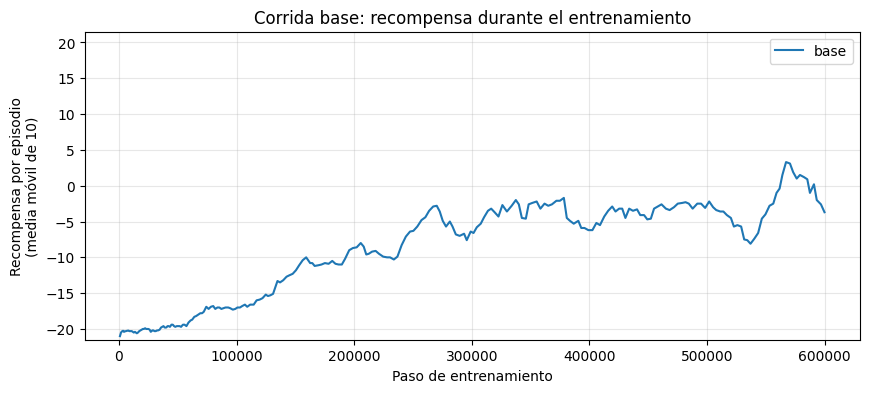

corrida  episodios  media últimos 10  mejor media móvil  paso en que media ≥ -15  minutos
   base        246              -3.7                3.3                   134780    99.41


In [23]:
res_base = cargar_resultados("base")
graficar_recompensas({"base": res_base}, titulo="Corrida base: recompensa durante el entrenamiento",
                     archivo="recompensa_base.png")
print(tabla_resumen({"base": res_base}, hasta=CONFIG_BASE["pasos_totales"]).to_string(index=False))

**Análisis de la corrida base:** _(se completa con los resultados de la ejecución)_

### 6.5 Estrategia de exploración ε-greedy (actividad 2)

ε controla cuánto explora el agente. En Pong, al principio casi todo es aleatorio y el agente pierde 21-0; necesita explorar lo suficiente para ver alguna vez que devolver la pelota da puntos, pero si explora demasiado tiempo pierde puntos que ya sabría ganar.

Se comparan tres calendarios con todo lo demás igual:

- **base:** 1.0 → 0.02 en 100 000 pasos.
- **eps_rapido:** 1.0 → 0.02 en 20 000 pasos. Explora poco; se espera que mejore antes, con el riesgo de quedarse en una política pobre.
- **eps_lento:** 1.0 → 0.10 en 250 000 pasos. Explora mucho y nunca baja de 10 % de acciones al azar; las recompensas de entrenamiento salen castigadas por eso.

Ojo: la recompensa durante el entrenamiento incluye las acciones al azar. Para separar "aprendió menos" de "explora más", las tres se evalúan también con ε = 0.01 en la sección 6.8.

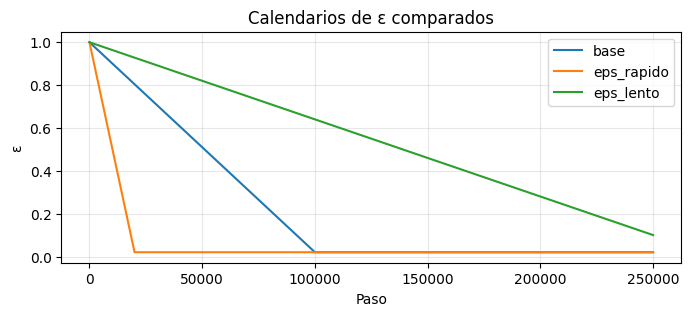

In [24]:
# Cómo baja ε en cada configuración
CAMBIOS_EPS = {
    "eps_rapido": dict(eps_pasos=20_000, pasos_totales=PASOS_COMPARACION),
    "eps_lento": dict(eps_final=0.10, eps_pasos=250_000, pasos_totales=PASOS_COMPARACION),
}
pasos = np.arange(0, PASOS_COMPARACION + 1, 1_000)
plt.figure(figsize=(8, 3))
for nombre, cambios in [("base", {})] + list(CAMBIOS_EPS.items()):
    cfg = {**CONFIG_BASE, **cambios}
    plt.plot(pasos, [epsilon(p, cfg) for p in pasos], label=nombre)
plt.xlabel("Paso"); plt.ylabel("ε"); plt.title("Calendarios de ε comparados")
plt.grid(alpha=0.3); plt.legend()
guardar_figura("calendarios_epsilon.png")
plt.show()

In [25]:
res_eps_rapido = entrenar("eps_rapido", CAMBIOS_EPS["eps_rapido"])

ep    5 | paso    4,490 | recompensa  -20.0 | media últimos 10  -20.4 | ε 0.780 |    0.1 min |   911 pasos/s
ep   10 | paso    8,985 | recompensa  -21.0 | media últimos 10  -20.4 | ε 0.560 |    0.2 min |   712 pasos/s
ep   15 | paso   13,208 | recompensa  -21.0 | media últimos 10  -20.7 | ε 0.353 |    0.8 min |   288 pasos/s
ep   20 | paso   17,703 | recompensa  -21.0 | media últimos 10  -20.5 | ε 0.133 |    1.5 min |   196 pasos/s
ep   25 | paso   22,430 | recompensa  -18.0 | media últimos 10  -20.0 | ε 0.020 |    2.3 min |   161 pasos/s
ep   30 | paso   27,950 | recompensa  -19.0 | media últimos 10  -19.8 | ε 0.020 |    3.3 min |   142 pasos/s
ep   35 | paso   35,293 | recompensa  -18.0 | media últimos 10  -18.8 | ε 0.020 |    4.6 min |   128 pasos/s
ep   40 | paso   43,559 | recompensa  -20.0 | media últimos 10  -18.1 | ε 0.020 |    6.0 min |   121 pasos/s
ep   45 | paso   53,191 | recompensa  -15.0 | media últimos 10  -18.0 | ε 0.020 |    7.7 min |   116 pasos/s
ep   50 | paso   65

In [ ]:
res_eps_lento = entrenar("eps_lento", CAMBIOS_EPS["eps_lento"])

ep    5 | paso    4,793 | recompensa  -19.0 | media últimos 10  -20.0 | ε 0.983 |    0.1 min |   894 pasos/s
ep   10 | paso    9,312 | recompensa  -21.0 | media últimos 10  -20.4 | ε 0.966 |    0.2 min |   976 pasos/s
ep   15 | paso   14,211 | recompensa  -20.0 | media últimos 10  -20.6 | ε 0.949 |    0.8 min |   306 pasos/s
ep   20 | paso   18,980 | recompensa  -19.0 | media últimos 10  -20.1 | ε 0.932 |    1.4 min |   221 pasos/s
ep   25 | paso   24,005 | recompensa  -20.0 | media últimos 10  -19.8 | ε 0.914 |    2.1 min |   188 pasos/s
ep   30 | paso   29,235 | recompensa  -19.0 | media últimos 10  -19.9 | ε 0.895 |    2.9 min |   170 pasos/s
ep   35 | paso   34,077 | recompensa  -20.0 | media últimos 10  -20.3 | ε 0.877 |    3.5 min |   160 pasos/s
ep   40 | paso   38,959 | recompensa  -21.0 | media últimos 10  -20.3 | ε 0.860 |    4.2 min |   154 pasos/s
ep   45 | paso   43,863 | recompensa  -21.0 | media últimos 10  -20.5 | ε 0.842 |    4.9 min |   149 pasos/s
ep   50 | paso   48

In [ ]:
corridas_eps = {n: cargar_resultados(n) for n in ["base", "eps_rapido", "eps_lento"]}
graficar_recompensas(corridas_eps, hasta=PASOS_COMPARACION,
                     titulo="Efecto del calendario de ε (primeros 250 000 pasos)", archivo="comparacion_epsilon.png")
print(tabla_resumen(corridas_eps, hasta=PASOS_COMPARACION).to_string(index=False))

**Análisis de la exploración:** _(se completa con los resultados de la ejecución)_

### 6.6 Valores Q, objetivos TD y error TD (actividad 3)

Tres gráficas por corrida:

1. **Q predicho vs objetivo TD.** El Q que la red asigna a la acción tomada contra el objetivo Double DQN calculado con la red objetivo. Si el Q predicho va siempre por encima del objetivo, hay sobreestimación.
2. **|error TD| y pérdida Huber.** No tienen por qué bajar a cero: el objetivo cambia cada vez que se sincroniza la red objetivo y cuando la política mejora. Lo preocupante sería que crezcan sin control.
3. **Q máximo medio en 500 estados fijos.** Mide la escala de los valores Q. Con γ = 0.99 y recompensas de ±1, un Q cerca de 0 indica puntos ganados y perdidos parejos, uno negativo que el agente espera perder, y valores que crecen sin parar serían señal de divergencia.

Recordatorio: los objetivos TD son estimaciones construidas con la misma red (*bootstrapping*), no los valores Q reales. Para tener una referencia real, en la sección 6.8 se compara el Q que predice la red durante la evaluación con el retorno descontado que de verdad obtuvo el agente desde cada estado.

In [ ]:
def graficar_q(nombre, archivo=None):
    res = cargar_resultados(nombre)
    tr, qf = res["entrenamiento"], res["q_fijos"]
    fig, ax = plt.subplots(1, 3, figsize=(17, 4))
    ax[0].plot(tr["paso"], tr["q_pred"], label="Q predicho (acción tomada)")
    ax[0].plot(tr["paso"], tr["objetivo_td"], label="objetivo TD Double DQN", alpha=0.8)
    ax[0].set_title("Q predicho vs objetivo TD")
    ax[1].plot(tr["paso"], tr["error_td"], label="|error TD| medio")
    ax[1].plot(tr["paso"], tr["perdida"], label="pérdida Huber", alpha=0.8)
    ax[1].set_title("Error de diferencia temporal")
    ax[2].plot(qf["paso"], qf["q_max_medio"], marker="o", markersize=3)
    ax[2].set_title("Q máximo medio en 500 estados fijos")
    for a in ax:
        a.set_xlabel("Paso"); a.grid(alpha=0.3)
    ax[0].legend(); ax[1].legend()
    fig.suptitle(f"Corrida {nombre}", y=1.02)
    plt.tight_layout()
    guardar_figura(archivo)
    plt.show()

graficar_q("base", archivo="q_td_base.png")

**Análisis de los valores Q:** _(se completa con los resultados de la ejecución)_

### 6.7 Arquitectura (actividad 4)

**Revisión de la red original.** Es la red de Mnih et al. (2015): tres convoluciones (32 filtros 8×8 paso 4, 64 de 4×4 paso 2, 64 de 3×3 paso 1), una densa de 512 con ReLU y una salida lineal con un Q por acción. Sobre lo que pide revisar el taller:

- **Convoluciones:** los filtros grandes con paso 4 reducen 84×84 a 20×20 en la primera capa; para Pong basta, porque solo hay que ubicar dos raquetas y una pelota. Tres capas son suficientes: el problema es visualmente simple.
- **Activaciones:** ReLU en capas ocultas es estándar. La salida debe ser lineal porque los valores Q no están acotados a un rango fijo.
- **Sin BatchNorm ni Dropout,** a propósito: los objetivos cambian todo el tiempo y la normalización por lote interactúa mal con eso.
- **Densa:** concentra casi todos los parámetros (3 136 × 512 ≈ 1.6 M de 1.69 M). Una sola cabeza tiene que aprender a la vez qué tan bueno es el estado y qué acción conviene.

**Modificación propuesta: cabeza Dueling** (Wang et al., 2016). La salida se separa en V(s), el valor del estado, y A(s,a), la ventaja de cada acción, y se combinan como Q = V + A − promedio(A). La razón para Pong: en muchos estados la acción casi no importa (la pelota va hacia el rival), y con la cabeza Dueling la red puede aprender V(s) en esos estados sin tener que ajustar cada Q por separado. Las convoluciones son las mismas y las dos ramas de 256 neuronas dejan casi el mismo número de parámetros que la densa de 512, así que la comparación mide el efecto de la estructura y no de una red más grande.

In [ ]:
res_dueling = entrenar("dueling", dict(arquitectura="dueling", pasos_totales=PASOS_COMPARACION))

In [ ]:
corridas_arq = {"base (original)": cargar_resultados("base"), "dueling": cargar_resultados("dueling")}
graficar_recompensas(corridas_arq, hasta=PASOS_COMPARACION,
                     titulo="Red original vs Dueling (primeros 250 000 pasos)", archivo="comparacion_arquitectura.png")
print(tabla_resumen(corridas_arq, hasta=PASOS_COMPARACION).to_string(index=False))
graficar_q("dueling", archivo="q_td_dueling.png")

**Análisis de la arquitectura:** _(se completa con los resultados de la ejecución)_

### 6.8 Evaluación de la política aprendida (actividad 5)

Cada agente juega 5 partidas completas (hasta 21 puntos) con las mismas semillas. Los agentes DQN usan ε = 0.01, es decir, casi siempre la acción de mayor Q.

- **Aleatorio:** referencia inferior.
- **Heurístico:** el de la sección 2, que sigue la pelota. Se juega sobre `ALE/Pong-v5` con `frame_skip` 4 y acciones pegajosas (0.25), igual que `make_env`, para que la comparación sea justa.
- **DQN:** `base` a los 250 000 y a los 600 000 pasos, más `eps_rapido`, `eps_lento` y `dueling` a los 250 000.

En los agentes DQN también se guarda el Q medio de las acciones elegidas y el retorno descontado real desde cada estado. Si el Q medio queda muy por encima del retorno real, la red sobreestima.

In [ ]:
EPISODIOS_EVAL, SEMILLA_EVAL, EPS_EVAL = 5, 1000, 0.01


def jugar_aleatorio(episodios=EPISODIOS_EVAL, semilla=SEMILLA_EVAL):
    env, rng, filas = make_env(), random.Random(semilla), []
    for k in range(episodios):
        env.reset(seed=semilla + k)
        total, pasos, hecho = 0.0, 0, False
        while not hecho:
            _, r, terminated, truncated, _ = env.step(rng.randrange(N_ACCIONES))
            total += r; pasos += 1; hecho = terminated or truncated
        filas.append(dict(episodio=k + 1, puntaje=total, pasos=pasos))
    env.close()
    return pd.DataFrame(filas)


def jugar_heuristico(episodios=EPISODIOS_EVAL, semilla=SEMILLA_EVAL):
    # Pong-v5 usa por defecto frame_skip=4 y acciones pegajosas 0.25, igual que make_env
    env, filas = gym.make("ALE/Pong-v5", repeat_action_probability=0.25), []
    for k in range(episodios):
        obs, _ = env.reset(seed=semilla + k)
        total, pasos, hecho = 0.0, 0, False
        while not hecho:
            obs, r, terminated, truncated, _ = env.step(heuristic_agent(obs))
            total += r; pasos += 1; hecho = terminated or truncated
        filas.append(dict(episodio=k + 1, puntaje=total, pasos=pasos))
    env.close()
    return pd.DataFrame(filas)


def cargar_agente(nombre, archivo="online.weights.h5"):
    with open(os.path.join(CARPETA, nombre, "estado.json")) as f:
        cfg = json.load(f)["cfg"]
    agente = AgenteDDQN(N_ACCIONES, {**cfg, "buffer": 1})   # para jugar no se necesita buffer
    agente.model.load_weights(os.path.join(CARPETA, nombre, archivo))
    return agente


def jugar_ddqn(agente, episodios=EPISODIOS_EVAL, semilla=SEMILLA_EVAL, eps=EPS_EVAL, grabar=False):
    env, rng, filas, cuadros = make_env(), random.Random(semilla), [], []
    for k in range(episodios):
        s, _ = env.reset(seed=semilla + k)
        recompensas, qs, hecho = [], [], False
        while not hecho:
            q = agente.valores_q(np.asarray(s)[None]).numpy()[0]
            a = rng.randrange(N_ACCIONES) if rng.random() < eps else int(q.argmax())
            qs.append(q[a])
            s, r, terminated, truncated, _ = env.step(a)
            recompensas.append(r); hecho = terminated or truncated
            if grabar and k == 0 and len(recompensas) % 3 == 0 and len(cuadros) < 600:
                cuadros.append(env.unwrapped.ale.getScreenRGB())
        # Retorno descontado real desde cada estado, para contrastar con el Q que esperaba la red
        G, acum = np.zeros(len(recompensas)), 0.0
        for t in reversed(range(len(recompensas))):
            acum = recompensas[t] + agente.gamma * acum
            G[t] = acum
        filas.append(dict(episodio=k + 1, puntaje=sum(recompensas), pasos=len(recompensas),
                          q_medio=float(np.mean(qs)), retorno_desc_real=float(G.mean())))
    env.close()
    return pd.DataFrame(filas), cuadros

In [ ]:
corte = f"online_{PASOS_COMPARACION // 1000}k.weights.h5"
evaluaciones = {"aleatorio": jugar_aleatorio(), "heurístico": jugar_heuristico()}
cuadros_base = None
for etiqueta, nombre, archivo in [
    ("base 250k", "base", corte),
    ("eps_rapido 250k", "eps_rapido", corte),
    ("eps_lento 250k", "eps_lento", corte),
    ("dueling 250k", "dueling", corte),
    ("base 600k", "base", "online.weights.h5"),
]:
    if not os.path.exists(os.path.join(CARPETA, nombre, archivo)):
        print(f"Falta {nombre}/{archivo}; se omite.")
        continue
    agente = cargar_agente(nombre, archivo)
    evaluaciones[etiqueta], cuadros = jugar_ddqn(agente, grabar=(etiqueta == "base 600k"))
    if cuadros:
        cuadros_base = cuadros
    del agente

resumen_eval = pd.DataFrame([
    {"agente": k, "puntaje medio": v["puntaje"].mean(), "desv.": v["puntaje"].std(),
     "mín": v["puntaje"].min(), "máx": v["puntaje"].max(), "pasos medios": v["pasos"].mean(),
     "Q medio": v["q_medio"].mean() if "q_medio" in v else np.nan,
     "retorno desc. real": v["retorno_desc_real"].mean() if "retorno_desc_real" in v else np.nan}
    for k, v in evaluaciones.items()
]).round(2)
resumen_eval.to_csv(os.path.join(CARPETA, "evaluacion_final.csv"), index=False)
print(resumen_eval.to_string(index=False))

In [ ]:
# Puntaje por partida de cada agente
plt.figure(figsize=(10, 4))
etiquetas = list(evaluaciones)
plt.boxplot([evaluaciones[k]["puntaje"] for k in etiquetas])
plt.xticks(range(1, len(etiquetas) + 1), etiquetas, rotation=20)
plt.axhline(0, color="gray", linewidth=0.8)
plt.ylabel("Puntaje por partida (-21 a 21)")
plt.title(f"Evaluación: {EPISODIOS_EVAL} partidas por agente")
plt.grid(alpha=0.3, axis="y")
guardar_figura("evaluacion_final.png")
plt.show()

# Partida del agente base final (inicio de la primera partida)
if cuadros_base:
    imageio.mimsave("ddqn_base_final.gif", cuadros_base, fps=20)
    display(Image(filename="ddqn_base_final.gif"))

**Análisis de la evaluación:** _(se completa con los resultados de la ejecución)_

## 7. Conclusiones

_(Se escriben con los resultados de la ejecución.)_

## 8. Referencias

- ALE, API actual: https://ale.farama.org/main/getting-started/
- Gymnasium, wrappers: https://gymnasium.farama.org/
- Mnih, V. et al. (2015). Human-level control through deep reinforcement learning. *Nature*, 518, 529–533.
- van Hasselt, H., Guez, A. y Silver, D. (2016). Deep Reinforcement Learning with Double Q-learning. *AAAI*.
- Wang, Z. et al. (2016). Dueling Network Architectures for Deep Reinforcement Learning. *ICML*.
- Machado, M. C. et al. (2018). Revisiting the Arcade Learning Environment: Evaluation Protocols and Open Problems for General Agents. *JAIR*, 61, 523–562.